In [1]:

pip install "numpy<2.0"


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pyodbc
import pandas as pd

# Connexion
conn_str = (
    "Driver={ODBC Driver 17 for SQL Server};"
    "Server=LAPTOP-GPVK1ANC;"
    "Database=DW_SupplyChain;"
    "Trusted_Connection=yes;"
)
cnxn = pyodbc.connect(conn_str)

# Requête
query = """
SELECT 
    productFK,
    brandFK,
    Production_Start_Time,
    Production_End_Time,
    manufacturedate,
    expirydate,
    Dosage,
    quantityused
FROM fact_production
"""
df = pd.read_sql(query, cnxn)
df.head()


C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
C:\Users\ayadi\AppData\Local\Temp\ipykernel_12752\3215957079.py:26: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnxn)


,productFK,brandFK,Production_Start_Time,Production_End_Time,manufacturedate,expirydate,Dosage,quantityused
0,2,15,2022032723,2022032800,2024082023,2025083023,9,9
1,2,15,2022040823,2022040806,2024082023,2025083023,9,9
2,2,15,2022050523,2022050517,2024082023,2025083023,9,9
3,2,15,2022052123,2022052119,2024082023,2025083023,9,9
4,2,15,2022070123,2022070113,2024082023,2025083023,9,9


C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


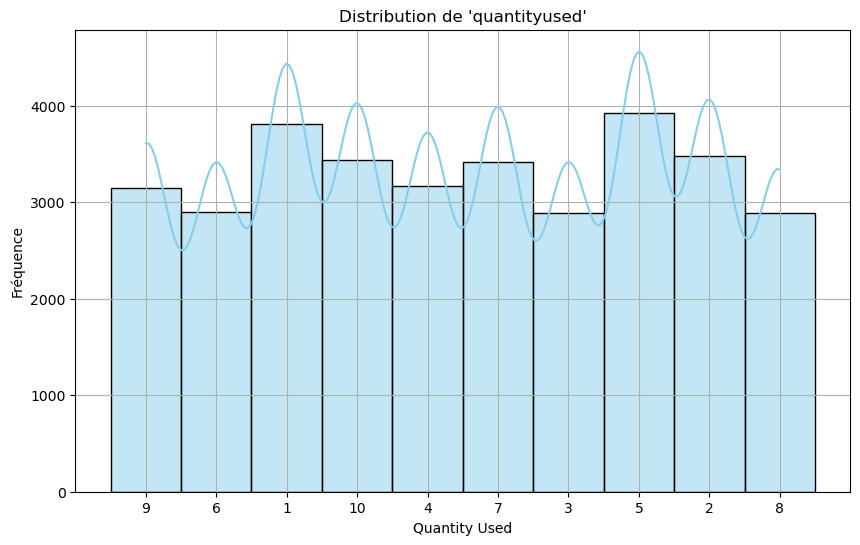

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['quantityused'], bins=30, kde=True, color='skyblue')
plt.title("Distribution de 'quantityused'")
plt.xlabel("Quantity Used")
plt.ylabel("Fréquence")
plt.grid(True)
plt.show()


In [4]:
# Vérifie le type de la colonne
print(df['quantityused'].dtype)

# Convertit en float (si certaines valeurs sont des chaînes)
df['quantityused'] = pd.to_numeric(df['quantityused'], errors='coerce')

# Vérifie s’il y a des NaN après conversion (valeurs non convertibles)
print(df['quantityused'].isnull().sum())


object
0


In [5]:
print(df['quantityused'].dtype)


int64


In [6]:
df['quantityused_cat'] = pd.qcut(
    df['quantityused'],
    q=4,
    labels=['Très Faible', 'Faible', 'Moyenne', 'Élevée']
)


In [7]:
print(df[['quantityused', 'quantityused_cat']].head(50))


    quantityused quantityused_cat
0              9           Élevée
1              9           Élevée
2              9           Élevée
3              9           Élevée
4              9           Élevée
5              9           Élevée
6              9           Élevée
7              9           Élevée
8              9           Élevée
9              9           Élevée
10             9           Élevée
11             9           Élevée
12             9           Élevée
13             9           Élevée
14             9           Élevée
15             9           Élevée
16             9           Élevée
17             9           Élevée
18             9           Élevée
19             9           Élevée
20             9           Élevée
21             9           Élevée
22             9           Élevée
23             9           Élevée
24             9           Élevée
25             9           Élevée
26             6          Moyenne
27             6          Moyenne
28            

In [8]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Encodage de la variable cible (classification supervisée)
label_encoder = LabelEncoder()
df['quantityused_cat_encoded'] = label_encoder.fit_transform(df['quantityused_cat'])

# Encodage des variables catégorielles (productFK, brandFK)
df['productFK'] = df['productFK'].astype(str)
df['brandFK'] = df['brandFK'].astype(str)

df_encoded = pd.get_dummies(df, columns=['productFK', 'brandFK'], drop_first=True)

# Extraction des features numériques (on exclut la cible encodée)
features = df_encoded.drop(columns=['quantityused', 'quantityused_cat', 'quantityused_cat_encoded',
                                    'Production_Start_Time', 'Production_End_Time',
                                    'manufacturedate', 'expirydate'])  # on supprime les colonnes non numériques

# Normalisation
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# Cible
target = df['quantityused_cat_encoded']


In [9]:
from sklearn.model_selection import train_test_split

# Séparation
X_train, X_test, y_train, y_test = train_test_split(
    features_scaled,
    target,
    test_size=0.2,        # 80% entraînement, 20% test
    random_state=42,      # reproductibilité
    stratify=target       # conserve les proportions de classes
)


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Modèle
rf_model = RandomForestClassifier(
    n_estimators=100,     # nombre d'arbres
    random_state=42,
    max_depth=None,       # profondeur max des arbres
    n_jobs=-1             # utilisation de tous les cœurs pour le calcul
)

# Entraînement
rf_model.fit(X_train, y_train)

# Prédiction
y_pred_rf = rf_model.predict(X_test)

# Évaluation
print("🎯 Random Forest Results :")
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf, target_names=label_encoder.classes_))


🎯 Random Forest Results :
[[1418    0    0    0]
 [   0 1841    0    0]
 [   0    0 2034    0]
 [   0    0    0 1316]]
              precision    recall  f1-score   support

      Faible       1.00      1.00      1.00      1418
     Moyenne       1.00      1.00      1.00      1841
 Très Faible       1.00      1.00      1.00      2034
      Élevée       1.00      1.00      1.00      1316

    accuracy                           1.00      6609
   macro avg       1.00      1.00      1.00      6609
weighted avg       1.00      1.00      1.00      6609



In [11]:
df.head(50)

,productFK,brandFK,Production_Start_Time,Production_End_Time,manufacturedate,expirydate,Dosage,quantityused,quantityused_cat,quantityused_cat_encoded
0,2,15,2022032723,2022032800,2024082023,2025083023,9,9,Élevée,3
1,2,15,2022040823,2022040806,2024082023,2025083023,9,9,Élevée,3
2,2,15,2022050523,2022050517,2024082023,2025083023,9,9,Élevée,3
3,2,15,2022052123,2022052119,2024082023,2025083023,9,9,Élevée,3
4,2,15,2022070123,2022070113,2024082023,2025083023,9,9,Élevée,3
5,2,15,2022082223,2022082218,2024082023,2025083023,9,9,Élevée,3
6,2,15,2022090323,2022090309,2024082023,2025083023,9,9,Élevée,3
7,2,15,2022091623,2022091616,2024082023,2025083023,9,9,Élevée,3
8,2,15,2022112923,2022112923,2024082023,2025083023,9,9,Élevée,3
9,2,15,2023010123,2023010112,2024082023,2025083023,9,9,Élevée,3


In [12]:
from sklearn.svm import SVC

# Création du modèle SVM (kernel RBF par défaut)
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)

# Entraînement
svm_model.fit(X_train, y_train)

# Prédiction
y_pred_svm = svm_model.predict(X_test)

# Évaluation
print("🧭 SVM Results :")
print(confusion_matrix(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm, target_names=label_encoder.classes_))


🧭 SVM Results :
[[1418    0    0    0]
 [   0 1841    0    0]
 [   0    0 2034    0]
 [   0    0    0 1316]]
              precision    recall  f1-score   support

      Faible       1.00      1.00      1.00      1418
     Moyenne       1.00      1.00      1.00      1841
 Très Faible       1.00      1.00      1.00      2034
      Élevée       1.00      1.00      1.00      1316

    accuracy                           1.00      6609
   macro avg       1.00      1.00      1.00      6609
weighted avg       1.00      1.00      1.00      6609



In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Modèle
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)

# Prédictions
y_pred_tree = tree_model.predict(X_test)

# Évaluation
print("🌳 Decision Tree Results :")
print(confusion_matrix(y_test, y_pred_tree))
print(classification_report(y_test, y_pred_tree, target_names=label_encoder.classes_))


🌳 Decision Tree Results :
[[1418    0    0    0]
 [   0 1841    0    0]
 [   0    0 2034    0]
 [   0    0    0 1316]]
              precision    recall  f1-score   support

      Faible       1.00      1.00      1.00      1418
     Moyenne       1.00      1.00      1.00      1841
 Très Faible       1.00      1.00      1.00      2034
      Élevée       1.00      1.00      1.00      1316

    accuracy                           1.00      6609
   macro avg       1.00      1.00      1.00      6609
weighted avg       1.00      1.00      1.00      6609



In [14]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, recall_score

# Prédictions pour chaque modèle
y_pred_rf = rf_model.predict(X_test)
y_pred_svm = svm_model.predict(X_test)
y_pred_tree = tree_model.predict(X_test)

# Matrice de confusion pour chaque modèle
cm_rf = confusion_matrix(y_test, y_pred_rf)
cm_svm = confusion_matrix(y_test, y_pred_svm)
cm_tree = confusion_matrix(y_test, y_pred_tree)

# Calcul des métriques pour chaque modèle
accuracy_rf = accuracy_score(y_test, y_pred_rf)
accuracy_svm = accuracy_score(y_test, y_pred_svm)
accuracy_tree = accuracy_score(y_test, y_pred_tree)

f1_rf = f1_score(y_test, y_pred_rf, average='weighted')
f1_svm = f1_score(y_test, y_pred_svm, average='weighted')
f1_tree = f1_score(y_test, y_pred_tree, average='weighted')

recall_rf = recall_score(y_test, y_pred_rf, average='weighted')
recall_svm = recall_score(y_test, y_pred_svm, average='weighted')
recall_tree = recall_score(y_test, y_pred_tree, average='weighted')

# Affichage des résultats
results = {
    'Model': ['Random Forest', 'SVM', 'Decision Tree'],
    'Accuracy': [accuracy_rf, accuracy_svm, accuracy_tree],
    'F1-Score': [f1_rf, f1_svm, f1_tree],
    'Recall': [recall_rf, recall_svm, recall_tree],
}

# Affichage des résultats sous forme de tableau
import pandas as pd
results_df = pd.DataFrame(results)
print(results_df)


           Model  Accuracy  F1-Score  Recall
0  Random Forest       1.0       1.0     1.0
1            SVM       1.0       1.0     1.0
2  Decision Tree       1.0       1.0     1.0


In [17]:
import pickle
import os

# 📦 Sauvegarder juste à côté du notebook (relatif)
save_path = "random_forest_model.pkl"

# 📌 Sauvegarder le modèle Random Forest
with open(save_path, 'wb') as f:
    pickle.dump(rf_model, f)

print(f"✅ Modèle Random Forest sauvegardé à côté du notebook : {save_path}")


✅ Modèle Random Forest sauvegardé à côté du notebook : random_forest_model.pkl


In [18]:
import pickle

# 📋 Récupérer les colonnes utilisées pour entraîner
model_columns = list(features.columns)

# 📦 Sauvegarder les colonnes dans un fichier
with open('random_forest_model_columns.pkl', 'wb') as f:
    pickle.dump(model_columns, f)

print("✅ Colonnes sauvegardées dans random_forest_model_columns.pkl")


✅ Colonnes sauvegardées dans random_forest_model_columns.pkl
